# Analysis of the learned controller

Why does the learned policy beat the LQR, which is optimal for its own problem? This notebook reads the final policies of the mass and energy experiment (`results/grid/`, GPOMDP + baseline, 5 seeds per pair) and drives them with the mean action, without noise, on the test episodes. The table of gains uses the whole grid. The later sections use the 5 policies at m = 75 kg and C = 0.5, the same as GPOMDP + baseline in `experiments.ipynb`. The last two sections use new experiments (`convergence` and `relative_targets`).

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from zamboni.controllers import PDController
from zamboni.env import (
    EPISODE_STEPS,
    MAX_FORCE,
    RINK_HALF_X,
    RINK_HALF_Y,
    TARGET_RADIUS,
    TARGET_WINDOW,
    ZamboniBatch,
)
from zamboni.features import RELATIVE_SCALE, VELOCITY_SCALE
from zamboni.policy import LinearGaussianPolicy
from zamboni.training import EVAL_EPISODES, TEST_SEED, evaluate, rollout

RESULTS = Path("../results")


def load(experiment):
    """All the runs of an experiment, each a dict with its configuration and its arrays."""
    runs = []
    for path in sorted((RESULTS / experiment).glob("*.npz")):
        data = np.load(path)
        config = json.loads(str(data["config"]))
        runs.append(config | {key: data[key] for key in data.files if key != "config"})
    return runs


def policy_of(run):
    policy = LinearGaussianPolicy()
    policy.theta = run["final_theta"]
    return policy


grid = load("grid")
central = [r for r in grid if r["mass"] == 75 and r["energy_coeff"] == 0.5]
policies = [policy_of(r) for r in central]  # the 5 seeds at m = 75 kg, C = 0.5
lqr = PDController.lqr(75.0, 0.5)

## What the policy learned

The mean action is linear, so its main weights read as gains, averaged over the two axes. kp pulls towards the target, kd brakes with the velocity, and the weights of x/30 and y/15 add a second pull towards the center of the rink, which the LQR does not have. With only these terms, and without the saturation, the motion is

    m a = kp (target - x) - pull x - kd v

The two springs together have stiffness kp + pull, so the damping ratio is ζ = kd / (2 sqrt((kp + pull) m)). It is 1 for critical damping, and below 1 the robot overshoots and oscillates.

In [2]:
def gains(theta):
    """kp in N/m, kd in N s/m and the pull towards the center in N/m, mean of the two axes."""
    W = theta[:-1].reshape(2, 8)
    return {
        "kp": MAX_FORCE / RELATIVE_SCALE * (W[0, 2] + W[1, 3]) / 2,
        "kd": -MAX_FORCE / VELOCITY_SCALE * (W[0, 4] + W[1, 5]) / 2,
        "pull": -MAX_FORCE * (W[0, 0] / RINK_HALF_X + W[1, 1] / RINK_HALF_Y) / 2,
    }


def mean_gains(runs):
    return {
        key: np.mean([gains(r["final_theta"])[key] for r in runs]) for key in ("kp", "kd", "pull")
    }


print("   m    C | learned: kp     kd  pull     ζ | LQR: kp     kd     ζ")
for mass in (50, 75, 100):
    for energy_coeff in (0.1, 0.5, 0.9):
        runs = [r for r in grid if r["mass"] == mass and r["energy_coeff"] == energy_coeff]
        g = mean_gains(runs)
        zeta = g["kd"] / (2 * np.sqrt((g["kp"] + g["pull"]) * mass))
        ref = PDController.lqr(mass, energy_coeff)
        ref_zeta = ref.kd / (2 * np.sqrt(ref.kp * mass))
        print(
            f"{mass:>4} {energy_coeff:>4} |     {g['kp']:>6.1f} {g['kd']:>6.1f} {g['pull']:>5.1f}"
            f" {zeta:>5.2f} | {ref.kp:>6.1f} {ref.kd:>6.1f} {ref_zeta:>5.2f}"
        )

   m    C | learned: kp     kd  pull     ζ | LQR: kp     kd     ζ
  50  0.1 |        3.1    5.7   1.2  0.19 |   29.9   56.2  0.73
  50  0.5 |        3.0    5.8   1.2  0.20 |   13.6   37.6  0.72
  50  0.9 |        2.9    5.9   1.2  0.21 |   10.2   32.5  0.72
  75  0.1 |        4.3    7.7   1.9  0.18 |   30.2   68.8  0.72
  75  0.5 |        4.1    8.2   1.9  0.19 |   13.7   46.0  0.72
  75  0.9 |        3.9    8.6   1.9  0.21 |   10.3   39.8  0.72
 100  0.1 |        5.0   10.0   2.7  0.18 |   30.4   79.5  0.72
 100  0.5 |        4.7   10.6   2.7  0.20 |   13.8   53.2  0.72
 100  0.9 |        4.4   11.1   2.6  0.21 |   10.3   45.9  0.72


In [3]:
MAIN = {(0, 0), (0, 2), (0, 4), (1, 1), (1, 3), (1, 5)}  # the weights read as gains above


def largest_other(W):
    """The largest weight in absolute value, outside the ones read as gains."""
    return max(abs(W[i, j]) for i in range(2) for j in range(8) if (i, j) not in MAIN)


single = max(largest_other(r["final_theta"][:-1].reshape(2, 8)) for r in grid)
mean = max(
    largest_other(np.mean([r["final_theta"][:-1].reshape(2, 8) for r in runs], axis=0))
    for runs in [
        [r for r in grid if r["mass"] == mass and r["energy_coeff"] == energy_coeff]
        for mass in (50, 75, 100)
        for energy_coeff in (0.1, 0.5, 0.9)
    ]
)
print(f"largest other weight: {mean:.2f} in the mean over the seeds, {single:.2f} in a single seed")

largest other weight: 0.09 in the mean over the seeds, 0.41 in a single seed


The learned gains are much softer than the LQR's (kp about 4 N/m against 10 to 30), the damping is weak (ζ about 0.2 against 0.72), and there is a pull towards the center of about 1 to 3 N/m. The learned controller does not chase the target as hard as it can: it moves towards it, overshoots, and swings back towards a point between the target and the center.

This reading keeps only the main weights. The others are at most 0.09 in the mean over the seeds, but they reach 0.41 in a single seed, so for a single policy it is a simplification.

## One episode

The same test episode (three targets, red) driven by the learned policy (seed 0) and by the LQR.

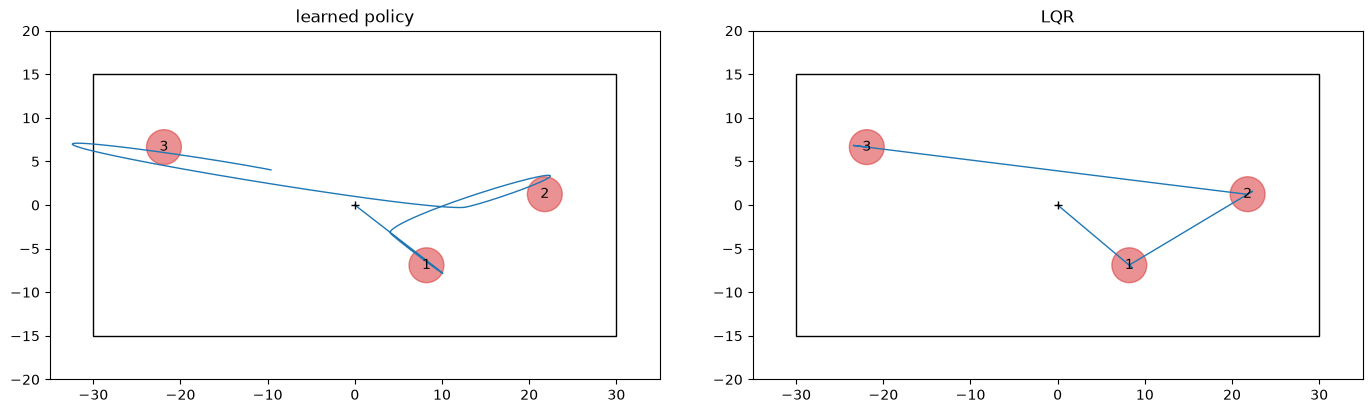

In [4]:
def episode_path(act, seed=0):
    batch = rollout(ZamboniBatch(1, 75.0, 0.5), act, np.random.default_rng(seed))
    return batch.states[:, 0, 0:2], batch.states[::TARGET_WINDOW, 0, 4:6]


fig, axes = plt.subplots(1, 2, figsize=(14, 4), layout="constrained")
for ax, (name, act) in zip(
    axes, [("learned policy", policies[0].act), ("LQR", lqr.act)], strict=True
):
    path, targets = episode_path(act)
    rink = plt.Rectangle((-RINK_HALF_X, -RINK_HALF_Y), 2 * RINK_HALF_X, 2 * RINK_HALF_Y, fill=False)
    ax.add_patch(rink)
    ax.plot(path[:, 0], path[:, 1], linewidth=1)
    for i, (tx, ty) in enumerate(targets, start=1):
        ax.add_patch(plt.Circle((tx, ty), TARGET_RADIUS, color="tab:red", alpha=0.5))
        ax.annotate(str(i), (tx, ty), ha="center", va="center")
    ax.plot(0, 0, "k+")
    ax.set_aspect("equal")
    ax.set_xlim(-RINK_HALF_X - 5, RINK_HALF_X + 5)
    ax.set_ylim(-RINK_HALF_Y - 5, RINK_HALF_Y + 5)
    ax.set_title(name)
plt.show()

The LQR goes straight to each target and stops on it. The learned policy reaches the first target, swings past it and back towards the center, and so on. In this episode it even leaves the rink while swinging past the third target (the base problem has no walls).

## Inside the target windows

For each policy, on the 1000 test episodes: the mean distance to the current target during its 20 s window, the share of targets reached, where the robot is when a window ends (which is where the next target finds it), and the speed at which it enters the 2 m disk.

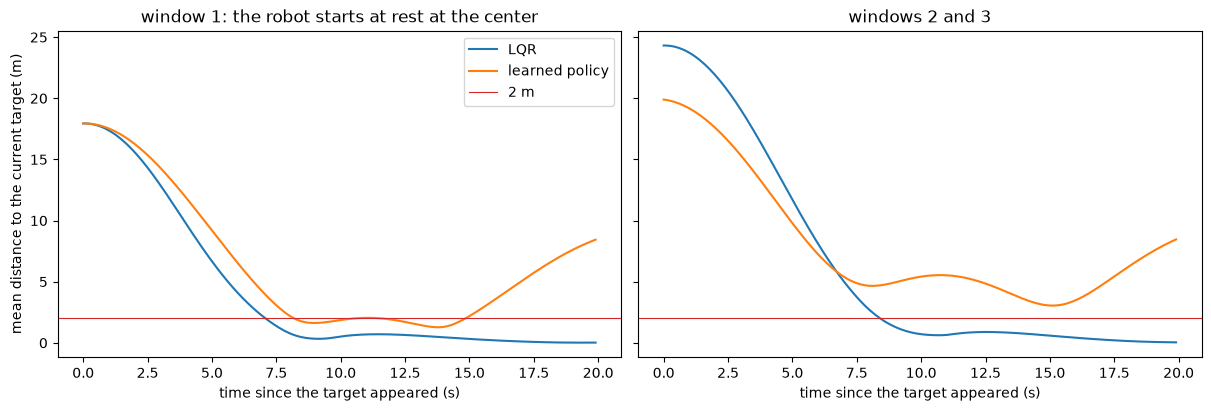

columns: reached in window 1, reached in windows 2-3, distance at the start of windows 2-3,
distance to the target and to the center at the window end, entry speed: median, above 3 m/s
LQR                 100%     100%     24.3m         0.0m        17.8m       1.7m/s       3%
learned policy       95%      62%     19.9m         8.5m         9.8m       1.9m/s      22%


In [5]:
def windows(act):
    sim = ZamboniBatch(EVAL_EPISODES, 75.0, 0.5)
    obs = sim.reset(np.random.default_rng(TEST_SEED))  # the test episodes of evaluate()
    n_windows = EPISODE_STEPS // TARGET_WINDOW
    distance = np.empty((n_windows, TARGET_WINDOW))
    reached, end_target, end_center = np.zeros(n_windows), np.empty(n_windows), np.empty(n_windows)
    entry_speeds = []
    for t in range(EPISODE_STEPS):
        w, k = divmod(t, TARGET_WINDOW)
        distance[w, k] = np.linalg.norm(obs[:, 0:2] - obs[:, 4:6], axis=1).mean()
        obs, _, info = sim.step(act(obs))
        reached[w] += info["reached_now"].mean()
        entry_speeds.append(info["speed"][info["reached_now"]])
        if k == TARGET_WINDOW - 1:  # the last step of the window
            end_target[w] = distance[w, k]
            end_center[w] = np.linalg.norm(sim.pos, axis=1).mean()
    return {
        "distance": distance,
        "reached": reached,
        "end_target": end_target,
        "end_center": end_center,
        "entry_speed": np.concatenate(entry_speeds),
    }


data = {"LQR": [windows(lqr.act)], "learned policy": [windows(p.act) for p in policies]}

seconds = np.arange(TARGET_WINDOW) * 0.1
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True, layout="constrained")
titles = ["window 1: the robot starts at rest at the center", "windows 2 and 3"]
for ax, rows, title in zip(axes, [slice(0, 1), slice(1, None)], titles, strict=True):
    for name, runs in data.items():
        curve = np.mean([d["distance"][rows].mean(axis=0) for d in runs], axis=0)
        ax.plot(seconds, curve, label=name)
    ax.axhline(TARGET_RADIUS, color="tab:red", linewidth=0.8, label="2 m")
    ax.set_xlabel("time since the target appeared (s)")
    ax.set_title(title)
axes[0].set_ylabel("mean distance to the current target (m)")
axes[0].legend()
plt.show()

print("columns: reached in window 1, reached in windows 2-3, distance at the start of windows 2-3,")
print(
    "distance to the target and to the center at the window end, entry speed: median, above 3 m/s"
)
for name, runs in data.items():
    stats = np.mean(
        [
            [
                d["reached"][0],
                d["reached"][1:].mean(),
                d["distance"][1:, 0].mean(),
                d["end_target"].mean(),
                d["end_center"].mean(),
                np.median(d["entry_speed"]),
                np.mean(d["entry_speed"] > 3.0),
            ]
            for d in runs
        ],
        axis=0,
    )
    print(
        f"{name:15} {stats[0]:>8.0%} {stats[1]:>8.0%} {stats[2]:>8.1f}m {stats[3]:>11.1f}m"
        f" {stats[4]:>11.1f}m {stats[5]:>9.1f}m/s {stats[6]:>8.0%}"
    )

The LQR reaches every target and stays on it until the window ends, 17.8 m from the center on average, so the next target starts 24.3 m away. The learned policy reaches 95% of the first targets but only 62% of the later ones. When a window ends it is 8.5 m from its target but only 9.8 m from the center, so the next target starts 19.9 m away. The cost sums the squared distance at every step, and a closer start makes the whole next window cheaper.

## Why the center

A new target is uniform on the rink, at least 2 m from the robot. Its expected squared distance, which is what the next window costs at its start, depends on where the robot is (200 000 draws).

In [6]:
print("expected squared distance of the next target")
rng = np.random.default_rng(0)
draws = rng.uniform([-RINK_HALF_X, -RINK_HALF_Y], [RINK_HALF_X, RINK_HALF_Y], size=(200_000, 2))
for position in [(0, 0), (10, 0), (20, 0), (28, 0), (0, 7), (0, 13)]:
    squared = np.sum((draws - position) ** 2, axis=1)
    squared = squared[squared > TARGET_RADIUS**2]  # the rule of the environment: not within 2 m
    print(f"robot at {str(position):8} {squared.mean():5.0f} m²")

expected squared distance of the next target
robot at (0, 0)     377 m²
robot at (10, 0)    478 m²
robot at (20, 0)    780 m²
robot at (28, 0)   1167 m²
robot at (0, 7)     427 m²
robot at (0, 13)    548 m²


From the center the next target is on average at 377 m², from (20, 0) at 780 m², twice as far in the cost. The LQR solves a problem with one fixed target and no next one. The learned policy is trained on the real task, with three targets in a row, and the gradient finds the compromise: waiting closer to the center costs some distance now and saves more later. The next section tests how much of the advantage this explains.

## Testing the explanation

The sections above show that the learned policy keeps closer to the center and that the center is a good place to wait, but not that this is what makes it win. Three direct tests, on the same test episodes:

1. Where the cost is paid, window by window, split into distance and energy, with the share of steps whose command is saturated (above 100 N).
2. The LQR with a pull towards the center added, the same kind of spring as the learned one: `u = LQR(s) - k x`.
3. The learned policies without their pull towards the center (the weights of x/30 and y/15 set to zero).

In [7]:
def cost_by_window(act):
    sim = ZamboniBatch(EVAL_EPISODES, 75.0, 0.5)
    obs = sim.reset(np.random.default_rng(TEST_SEED))
    n_windows = EPISODE_STEPS // TARGET_WINDOW
    distance, energy, saturated = np.zeros(n_windows), np.zeros(n_windows), 0.0
    for t in range(EPISODE_STEPS):
        w = t // TARGET_WINDOW
        obs, _, info = sim.step(act(obs))
        distance[w] += info["distance_cost"].mean()
        energy[w] += 0.5 / 100 * info["energy"].mean()  # C / 100 times the squared force
        saturated += info["saturated"].mean() / EPISODE_STEPS
    return distance, energy, saturated


print("cost per window in thousands, mean over the episodes (and over the 5 seeds)")
print("                 distance: w1    w2    w3 | energy: w1   w2   w3 | saturated")
rows = {
    "LQR": [cost_by_window(lqr.act)],
    "learned policy": [cost_by_window(p.act) for p in policies],
}
for name, results in rows.items():
    distance = np.mean([r[0] for r in results], axis=0) / 1e3
    energy = np.mean([r[1] for r in results], axis=0) / 1e3
    saturated = np.mean([r[2] for r in results])
    cells = (
        " ".join(f"{d:5.1f}" for d in distance) + " |      " + " ".join(f"{e:4.1f}" for e in energy)
    )
    print(f"{name:15}           {cells} | {saturated:8.1%}")

cost per window in thousands, mean over the episodes (and over the 5 seeds)
                 distance: w1    w2    w3 | energy: w1   w2   w3 | saturated


LQR                        12.9  30.5  31.8 |       1.7  2.4  2.4 |    12.6%
learned policy             16.9  21.5  23.2 |       1.4  1.9  2.1 |     3.7%


In [8]:
def lqr_with_pull(k):
    return lambda obs: lqr.act(obs) - k * obs[..., 0:2]  # a spring of k N/m towards the center


print("LQR with a pull towards the center, test return")
for k in (0.0, 1.0, 1.8, 3.0):
    print(f"  k = {k:3.1f} N/m: {evaluate(lqr_with_pull(k), 75.0, 0.5)['return'] / 1e3:6.1f}k")

without_pull = []
for p in policies:
    copy = LinearGaussianPolicy()
    copy.theta = p.theta
    copy.W[0, 0] = copy.W[1, 1] = 0.0  # the weights of x/30 and y/15
    without_pull.append(evaluate(copy.act, 75.0, 0.5)["return"])
with_pull = [evaluate(p.act, 75.0, 0.5)["return"] for p in policies]
print(f"learned policy: {np.mean(with_pull) / 1e3:6.1f}k")
print(f"learned policy without its pull: {np.mean(without_pull) / 1e3:6.1f}k")

LQR with a pull towards the center, test return
  k = 0.0 N/m:  -81.6k
  k = 1.0 N/m:  -77.2k
  k = 1.8 N/m:  -75.0k


  k = 3.0 N/m:  -73.6k


learned policy:  -67.0k
learned policy without its pull: -117.7k


The learned policy pays more than the LQR in the first window (16.9k against 12.9k) and much less in the second and the third, which start closer (about 22k against 31k). The energy is about the same. Adding to the LQR a pull towards the center like the learned one (1.8 N/m) improves it from −81.6k to −75.0k, and 3 N/m to −73.6k: the pull alone closes about half of the gap to the learned policy (−67.0k). Removing the pull from the learned policies makes them much worse (−118k), but their other gains were learned together with the pull, so this only says that the pull is essential for them.

The rest of the gap is most likely in the gains: the LQR is computed without the 100 N limit and saturates in about 13% of the steps, while the learned policy, trained with the limit, has much softer gains and saturates in about 4%. So the learned policy most likely wins because it is trained on the real task. It prepares for the next target, and with its softer gains its commands saturate less often.

In the third window there is no next target, yet the learned policy still swings back towards the center: the state holds the steps left in the window, not which window it is, so the policy cannot tell the third window from the second. A policy aware of the time left in the episode could stop doing it at the end.

## How lenient is "reached"

A target counts as reached when the robot comes within 2 m during its window, also when it only passes through. The table counts the targets reached with other radii (from the positions at every step), and the table above shows the entry speed: the learned policy enters the disk faster, 22% of the times above 3 m/s against 3% for the LQR.

In [9]:
radii = (0.5, 1.0, 2.0, 3.0, 5.0)


def reached_by_radius(act):
    batch = rollout(ZamboniBatch(EVAL_EPISODES, 75.0, 0.5), act, np.random.default_rng(TEST_SEED))
    distance = np.linalg.norm(batch.states[..., 0:2] - batch.states[..., 4:6], axis=-1)  # (T, n)
    per_window = distance.reshape(EPISODE_STEPS // TARGET_WINDOW, TARGET_WINDOW, -1)
    closest = per_window[:, 1:, :].min(axis=1)  # skip the step at which the target appears
    return [(closest <= r).sum(axis=0).mean() for r in radii]


print("targets reached out of 3, radius: " + "  ".join(f"{r:g} m" for r in radii))
print("LQR            ", np.round(reached_by_radius(lqr.act), 2))
print("learned policy ", np.round(np.mean([reached_by_radius(p.act) for p in policies], axis=0), 2))

targets reached out of 3, radius: 0.5 m  1 m  2 m  3 m  5 m
LQR             [3. 3. 3. 3. 3.]


learned policy  [0.9  1.53 2.19 2.57 2.91]


With 2 m the count matches the environment (2.19). The LQR reaches every target at any radius from 0.5 to 5 m. The count of the learned policy goes from 0.9 to 2.9 targets, so "targets reached" is a lenient metric for it and the return, the objective of the task, is the comparison that counts.

## A longer training

The central configuration trained again with twice the budget (200 000 episodes, K = 4000), 5 seeds, to see whether the result is limited by the training. The step size then decreases to zero over 4000 iterations instead of 2000.

In [10]:
def summary(runs):
    returns = np.array([r["test_return"] for r in runs])
    g = {key: np.mean([gains(r["final_theta"])[key] for r in runs]) for key in ("kp", "kd", "pull")}
    error = returns.std(ddof=1) / np.sqrt(len(returns))
    targets = np.mean([r["test_targets_reached"] for r in runs])
    return (
        f"{returns.mean() / 1e3:6.1f} ± {error / 1e3:3.1f}k, targets {targets:.2f},"
        f" kp {g['kp']:.1f}, kd {g['kd']:.1f}, pull {g['pull']:.1f}"
    )


print("100k episodes:", summary(central))
print("200k episodes:", summary(load("convergence")))

100k episodes:  -67.0 ± 0.4k, targets 2.19, kp 4.1, kd 8.2, pull 1.9
200k episodes:  -67.5 ± 0.8k, targets 2.35, kp 5.0, kd 10.7, pull 1.7


Doubling the budget does not improve the mean test return (−67.5 ± 0.8 against −67.0 ± 0.4 thousand), and the learned policy stays better than the LQR in both cases. The gains still move a little (kp from 4.1 to 5.0, kd from 8.2 to 10.7).

## Targets relative to the robot

If the pull towards the center comes from where the next target appears, it should weaken when the expected squared distance of the next target depends less on where the robot is. In this variant (`target_sampling="relative"`) we sample a direction and a distance between 5 and 30 m uniformly, then reject targets outside the rink. If none of the 32 proposals is valid, we draw an absolute target.

The central configuration is trained with it, with the hyperparameters chosen on absolute targets: 5 seeds with 100 000 episodes, and 5 with 200 000 (K = 4000, so the step size decreases over 4000 iterations). On the test episodes with relative targets the policies and the LQR share the random directions and distances, not the targets themselves.

First the expected squared distance of the next target, as in "Why the center", with the sampler of the environment (50 000 draws):

In [11]:
positions = [(0, 0), (10, 0), (20, 0), (28, 0), (0, 7), (0, 13)]
print("expected squared distance of the next target (m²)")
print(f"{'robot at':>9}" + "".join(f"{str(p):>10}" for p in positions))
for sampling in ("absolute", "relative"):
    sim = ZamboniBatch(50_000, target_sampling=sampling)
    sim.reset(np.random.default_rng(0))
    cells = []
    for position in positions:
        sim.pos[:] = position
        target = sim._draw_target()  # what the environment does when a window ends
        cells.append(np.mean(np.sum((target - sim.pos) ** 2, axis=1)))
    print(f"{sampling:>9}" + "".join(f"{c:>10.0f}" for c in cells))

expected squared distance of the next target (m²)
 robot at    (0, 0)   (10, 0)   (20, 0)   (28, 0)    (0, 7)   (0, 13)
 absolute       378       478       781      1166       426       546


 relative       266       226       212       253       289       341


With absolute targets the expected squared distance grows quickly away from the center, from 378 to 1166 m² along x. With relative targets it is much flatter along x, between 212 and 266 m². Along y it still grows towards the long edges, from 266 to 341 m², because the rink is only 30 m tall and the target must fall inside it.

In [12]:
def pull_per_axis(theta):
    """The pull towards the center in N/m along x and along y."""
    W = theta[:-1].reshape(2, 8)
    return -MAX_FORCE * W[0, 0] / RINK_HALF_X, -MAX_FORCE * W[1, 1] / RINK_HALF_Y


def saturated_share(act, target_sampling):
    """Share of the steps whose command is above 100 N, on the test episodes."""
    sim = ZamboniBatch(EVAL_EPISODES, 75.0, 0.5, target_sampling=target_sampling)
    obs = sim.reset(np.random.default_rng(TEST_SEED))
    share = 0.0
    for _ in range(EPISODE_STEPS):
        obs, _, info = sim.step(act(obs))
        share += info["saturated"].mean() / EPISODE_STEPS
    return share


relative = load("relative_targets")
rows = {
    "absolute, 100k": (central, "absolute"),
    "relative, 100k": ([r for r in relative if r["iterations"] == 2000], "relative"),
    "relative, 200k": ([r for r in relative if r["iterations"] == 4000], "relative"),
}
print(f"{'':18} {'test return':>14} {'targets':>8} {'saturated':>10} {'pull x':>7} {'pull y':>7}")
for name, (runs, sampling) in rows.items():
    returns = np.array([r["test_return"] for r in runs])
    error = returns.std(ddof=1) / np.sqrt(len(returns))
    targets = np.mean([r["test_targets_reached"] for r in runs])
    saturated = np.mean([saturated_share(policy_of(r).act, sampling) for r in runs])
    pull_x, pull_y = np.mean([pull_per_axis(r["final_theta"]) for r in runs], axis=0)
    print(
        f"PG  {name:14} {returns.mean() / 1e3:7.1f} ± {error / 1e3:3.1f}k {targets:>8.2f}"
        f" {saturated:>10.1%} {pull_x:>7.2f} {pull_y:>7.2f}"
    )
for sampling in ("absolute", "relative"):
    result = evaluate(lqr.act, 75.0, 0.5, target_sampling=sampling)
    print(
        f"LQR {sampling:14} {result['return'] / 1e3:7.1f}k {'':5} {result['targets_reached']:>8.2f}"
        f" {saturated_share(lqr.act, sampling):>10.1%}"
    )
print("PG as mean ± standard error over 5 seeds")

                      test return  targets  saturated  pull x  pull y


PG  absolute, 100k   -67.0 ± 0.4k     2.19       3.7%    1.85    1.92


PG  relative, 100k   -34.7 ± 1.5k     2.53       0.7%    0.43    1.69


PG  relative, 200k   -31.5 ± 0.4k     2.83       2.0%    0.46    1.34
LQR absolute         -81.6k           3.00      12.6%


LQR relative         -30.0k           3.00       6.9%
PG as mean ± standard error over 5 seeds


Along x the pull drops from 1.85 to 0.43 N/m. Along y the expected squared distance increases from 266 to 341 m² near the edge. The learned pull decreases from 1.92 to 1.69 N/m. This supports the idea that the pull comes from where the next target appears, but it does not prove it: relative targets also change the distances and the states the robot visits. With 200 000 episodes the pulls are 0.46 and 1.34 N/m.

With relative targets the LQR is better than the learned policy: −30.0 against −34.7 thousand, and −31.5 with 200 000 episodes. Our policy can represent the LQR controller, but these training runs give worse returns. This result does not tell which change matters: besides the next target, the saturation changes too. The LQR saturates in 6.9% of the steps with relative targets, against 12.6% with absolute ones.

The returns of the two variants are not comparable with each other, because the problem changes. The comparison is between the learned policy and the LQR within each variant.